# DTU dataset, clean speech

The single-talker trials of the DTU dataset (Fuglsang, Dau & Hjortkjaer 2017), analysed as this project's `clean.ipynb`: does adding the onset spectrogram, or the envelope spectrogram, improve the prediction of held-out EEG (one-tailed TFCE over the whole scalp)? The ROI-averaged tests and the response functions use this project's clean-speech ROI (`roi.txt`, from the cocktail clean-speech whole-scalp tests), the same ROI as every DTU two-talker notebook. DTU's single-talker trials are ten repetitions of one 50 s speech clip.

**How the data were prepared** (`dtu/dtu_pipeline.py`, on the cluster; run from `dtu.ipynb`), aligned with this project step for step:
- EEG: the raw recordings, preprocessed as this project's pipeline: bad channels by neighbour correlation, 0.5-20 Hz, mastoid reference, extended-infomax ICA with ICLabel (eye blinks, heart beats at >= 0.9), 64 Hz; trials cut at the trigger events as the authors' script does
- Trials: from the authors' trial table (stories, attended talker, single or two talkers, room)
- Predictors: 8-band gammatone envelope and onsets, made exactly as this project's; the mixture from the two stories summed (the rooms were simulated at presentation, so the exact mixture at the ears is not available)
- TRFs: the same boosting settings (-100 to 400 ms, 50 ms basis, l1, cross-validated)
- Tests: as this project's clean-speech notebook (one-tailed TFCE over the whole scalp, and the t-test on the mean over this project's ROI)

**Results come from the cluster**: run `dtu_run()` in `dtu.ipynb` first; this notebook only reads them.

In [1]:
# Reloads the code every time it runs, so changes pulled from GitHub take effect without
# restarting the kernel (Run All is enough).
import importlib, sys
for _module in ('experiment', 'parameters'):
    if getattr(sys.modules.get(_module), '__spec__', None):
        importlib.reload(sys.modules[_module])
from parameters import *

In [2]:
# The clean-speech results: model tests over the whole scalp; ROI means and TRFs in this project's ROI
ROI = dtu_setup('clean')

DTU clean: 18 subjects, 10 trials of 50 s each.
ROI, this project's clean-speech ROI (18 sensors): AF3, F1, F3, F5, F7, FC5, FC3, C1, C3, C5, AF4, AFz, F6, FT8, FC6, FC4, FC2, C2
Model tests over the whole scalp (as this project's clean speech); ROI means and TRFs in the ROI above.


In [3]:
# The full clean-speech model's TRFs (attended envelope and onsets)
data_full = dtu_trfs('clean')

<small>

**Onset (DTU clean speech), test - baseline**: does adding the onset spectrogram improve the prediction?

</small>

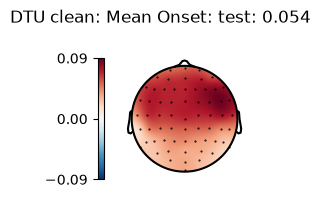

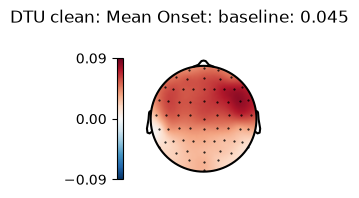

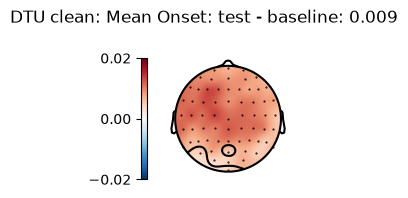

In [4]:
data, diff, result = dtu_model_test('Onset', 'clean')
show_topomap_trio(data, diff, result, 'Onset', 'DTU clean', None)

In [5]:
display(result)
print(f"Onset (DTU clean): TFCE {tfce_summary(result)}")
ttest = test.TTestOneSample(f'roi_{METRIC}', data=diff, tail=1)
print(f"Onset (DTU clean): ROI model comparison t({ttest.df}) = {ttest.t:.3f}, p = {ttest.p:.4f}")

<TTestRelated 'r', 'model', 'test', 'baseline', 'subject' (n=18), tail=1, samples=10000, tfce=True, p < .001>

Onset (DTU clean): TFCE t_max = 7.11, p < 0.001
Onset (DTU clean): ROI model comparison t(17) = 6.940, p = 0.0000


<small>

**Envelope (DTU clean speech), test - baseline**: does adding the envelope spectrogram improve the prediction?

</small>

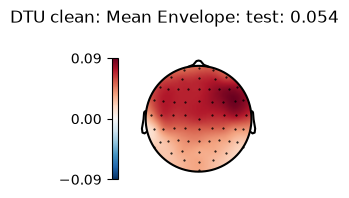

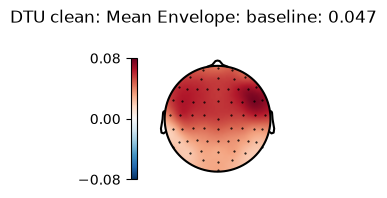

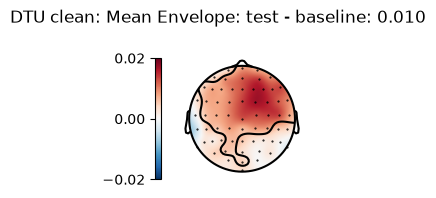

In [6]:
data, diff, result = dtu_model_test('Envelope', 'clean')
show_topomap_trio(data, diff, result, 'Envelope', 'DTU clean', None)

In [7]:
display(result)
print(f"Envelope (DTU clean): TFCE {tfce_summary(result)}")
ttest = test.TTestOneSample(f'roi_{METRIC}', data=diff, tail=1)
print(f"Envelope (DTU clean): ROI model comparison t({ttest.df}) = {ttest.t:.3f}, p = {ttest.p:.4f}")

<TTestRelated 'r', 'model', 'test', 'baseline', 'subject' (n=18), tail=1, samples=10000, tfce=True, p < .001>

Envelope (DTU clean): TFCE t_max = 5.64, p < 0.001
Envelope (DTU clean): ROI model comparison t(17) = 4.217, p = 0.0003


## Clean speech response functions

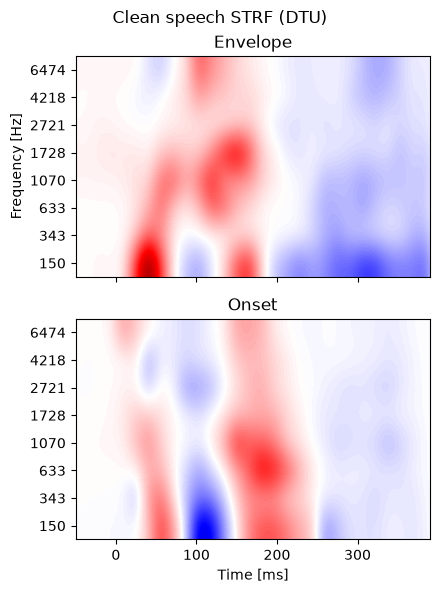

In [8]:
envelope_strf = extract_strf(data_full, 'gammatone_8')
onset_strf = extract_strf(data_full, 'gammatone_on_8')
p = plot.Array([envelope_strf * 1e3, onset_strf * 1e3], axtitle=['Envelope', 'Onset'],
               title='Clean speech STRF (DTU)', interpolation=STRF_INTERPOLATION, xlim=PLOT_WINDOW)

Onset (DTU clean) positive peak: 177 ms, amp 0.006416
Onset (DTU clean) negative peak: 107 ms, amp -0.004664


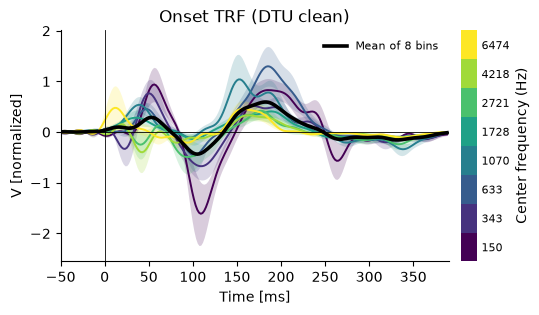

In [9]:
data = extract_trf(data_full, 'gammatone_on_8')
data = add_anchored_peak(data, 'positive', ONSET_POSITIVE_PEAK_WINDOW, kind='max')
data = add_anchored_peak(data, 'negative', ONSET_NEGATIVE_PEAK_WINDOW, kind='min')
print(f"Onset (DTU clean) positive peak: {data['positive_time'].mean() * 1e3:.0f} ms, amp {data['positive_amp'].mean():.4g}")
print(f"Onset (DTU clean) negative peak: {data['negative_time'].mean() * 1e3:.0f} ms, amp {data['negative_amp'].mean():.4g}")
p = plot_trf_bins(data_full, 'gammatone_on_8', 'Onset TRF (DTU clean)')

/Users/joshuaighalo/Github Repositories/cocktail-cortical/analysis/experiment.py:2404: UserWarning: negative anchor (all) at 199 ms is on the edge of the search window (0.02, 0.2)
  warnings.warn(f"{name} anchor ({label}) at {times[i] * 1e3:.0f} ms is on the edge of the search window {window}")


Envelope (DTU clean) positive peak: 150 ms, amp 0.005483
Envelope (DTU clean) negative peak: 194 ms, amp -0.0003279


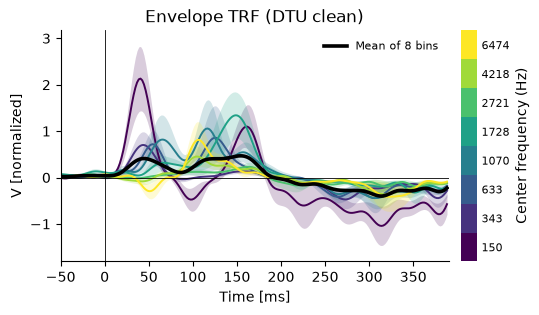

In [10]:
data = extract_trf(data_full, 'gammatone_8')
data = add_anchored_peak(data, 'positive', ENVELOPE_POSITIVE_PEAK_WINDOW, kind='max')
data = add_anchored_peak(data, 'negative', ENVELOPE_NEGATIVE_PEAK_WINDOW, kind='min')
print(f"Envelope (DTU clean) positive peak: {data['positive_time'].mean() * 1e3:.0f} ms, amp {data['positive_amp'].mean():.4g}")
print(f"Envelope (DTU clean) negative peak: {data['negative_time'].mean() * 1e3:.0f} ms, amp {data['negative_amp'].mean():.4g}")
p = plot_trf_bins(data_full, 'gammatone_8', 'Envelope TRF (DTU clean)')